# 2 The Maximal Overlap Discrete Wavelet Transform: Concepts and Implementation

## 2.6 MODWTMRA Implementation in Python

### 2.6.2 Example Usage

In [11]:
import numpy as np
from modwtpy.modwt import modwt, modwtmra

# Example signal
signal = np.random.randn(512)
wavelet = 'db4'
level = 4

# Perform MODWT
wt = modwt(signal, wavelet, level)   # returns only the coefficient matrix

# Perform MODWTMRA
mra_components = modwtmra(wt, wavelet)  # now only wt and wavelet needed

print("MRA shape:", mra_components.shape)
print("Reconstruction error:", np.max(np.abs(signal - np.sum(mra_components, axis=0))))

MRA shape: (5, 512)
Reconstruction error: 8.881784197001252e-16


## 2.7 Real-World Example: S&P 500 Stock Market Analysis

### 2.7.1 Quick MODWTMRA Example

### 2.7.1  Prepare Data

In [4]:
import os
import pandas as pd
from datetime import datetime, timedelta
import yfinance as yf

def prepare_data(data_path='./data/sp500.csv', ticker='^GSPC', days=730):
    """
    Load S&P 500 data from local CSV if available, else download from Yahoo Finance.
    Returns a DataFrame with Date as index and columns: Open, High, Low, Close, Volume.
    
    Handles MultiIndex CSV with headers: Price, Close, High, Low, Open, Volume under ^GSPC.
    """
    # Use an absolute path to avoid potential OS-specific issues with relative paths
    abs_data_path = os.path.abspath(data_path)
    data_dir = os.path.dirname(abs_data_path)
    os.makedirs(data_dir, exist_ok=True)

    data_df = None

    try:
        # Attempt to load the local file with MultiIndex headers
        if os.path.exists(abs_data_path):
            print(f"Loading S&P 500 data from {abs_data_path}")
            data_df = pd.read_csv(
                abs_data_path,
                header=[0, 1],  # Read two rows as MultiIndex headers
                parse_dates=[0],  # Parse the first column (Date) as datetime
                index_col=0  # Use the first column as the index
            )
            # Flatten MultiIndex to match yf.download structure
            # Assuming columns are like ('Price', '^GSPC'), ('Close', '^GSPC'), etc.
            data_df.columns = [col[0] if col[0] != 'Price' else 'Open' for col in data_df.columns]
    except (OSError, pd.errors.ParserError) as e:
        print(f"Could not load local file due to: {e}")
        print("Downloading a new copy from Yahoo Finance...")
        
    if data_df is None or data_df.empty:
        end = datetime.now()
        start = end - timedelta(days=days)
        
        # Download data, auto-adjust for splits and dividends, and save to CSV
        data_df = yf.download(ticker, start=start, end=end, auto_adjust=True)
        
        # Ensure 'Date' column is present before saving to CSV
        if not data_df.index.name:
            data_df.index.name = 'Date'
        
        # Save with MultiIndex to match original CSV structure
        data_df.columns = pd.MultiIndex.from_tuples(
            [('Price' if col == 'Open' else col, '^GSPC') for col in data_df.columns]
        )
        data_df.to_csv(abs_data_path)
        print(f"Data saved to {abs_data_path}")
        
        # Reload to return flattened columns
        data_df = data_df.copy()
        data_df.columns = [col[0] if col[0] != 'Price' else 'Open' for col in data_df.columns]
        
    return data_df

# Call the function and print the first few rows
data_df = prepare_data()
print(data_df.head())

Loading S&P 500 data from e:\project-workspace\jupyter-books\wavelet-book\script\data\sp500.csv
                  Close         High          Low         Open      Volume
Date                                                                      
2023-09-14  4505.100098  4511.990234  4478.689941  4487.779785  3648720000
2023-09-15  4450.319824  4497.979980  4447.209961  4497.979980  6932230000
2023-09-18  4453.529785  4466.359863  4442.109863  4445.129883  3161230000
2023-09-19  4443.950195  4449.850098  4416.609863  4445.410156  3614880000
2023-09-20  4402.200195  4461.029785  4401.379883  4452.810059  3308450000


### 2.7.2 Quick MODWTMRA Example

Loading S&P 500 data from e:\project-workspace\jupyter-books\wavelet-book\script\data\sp500.csv
Max reconstruction error: 9.09e-12


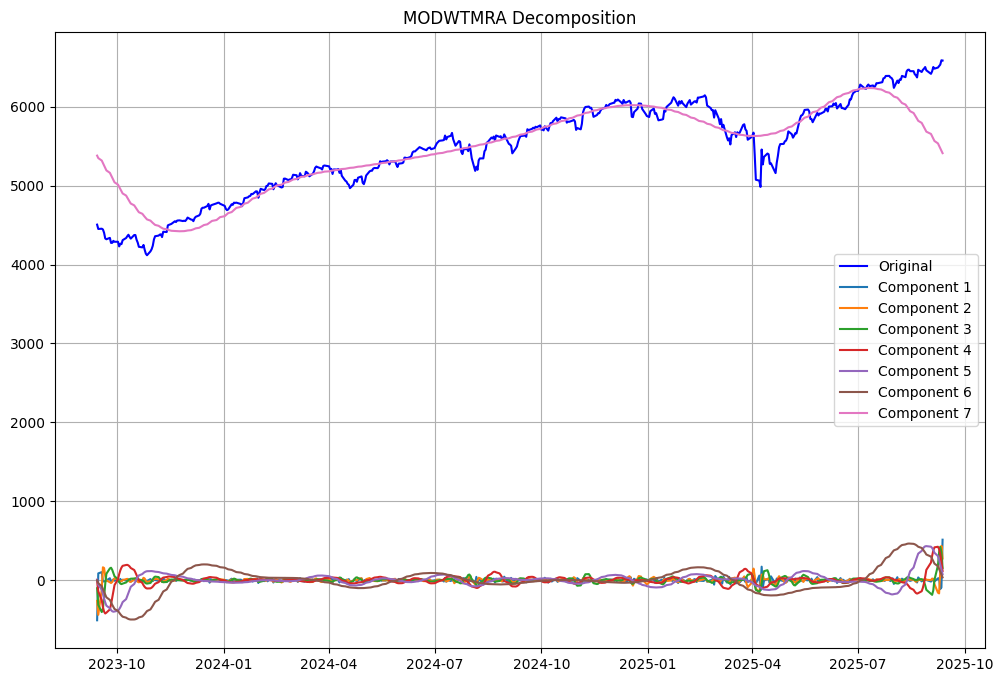

In [ ]:
import matplotlib.pyplot as plt
from modwtpy.modwt import modwt, modwtmra
import numpy as np
import pandas as pd

# Load data
data_df = prepare_data()

# Extract closing prices and dates
data = data_df['Close'].values
dates = data_df.index

# MODWT decomposition
wavelet = 'db4'
level = 6
wt = modwt(data, wavelet, level)
mra = modwtmra(wt, wavelet)
# Verify reconstruction
recon_error = np.max(np.abs(data - np.sum(mra, axis=0)))
print(f"Max reconstruction error: {recon_error:.2e}")
# Plot original + components
plt.figure(figsize=(12, 8))
plt.plot(dates, data, label='Original', color='blue')
for i, comp in enumerate(mra):
    plt.plot(dates, comp, label=f'Component {i+1}')
plt.legend()
plt.title('MODWTMRA Decomposition')
plt.grid(True)
plt.savefig('./output/modwtmra_decomposition.png', dpi=300)
plt.show()

## 2.8 MODWTMRA Analysis

### 2.8.2 Function Implementation

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from modwtpy.modwt import modwt, modwtmra
import pywt

def analyze_modwtmra(signal, wavelet, level, plot=False, compute_stats=False, dates=None, signal_name='Signal'):
    """
    Perform Maximal Overlap Discrete Wavelet Transform Multiresolution Analysis (MODWTMRA)
    on a given signal, with options for plotting and statistical computation.
    """

    # Input validation
    if not isinstance(signal, np.ndarray) or signal.ndim != 1 or len(signal) < 2:
        raise ValueError("signal must be a 1D NumPy array with length >= 2.")
    N = len(signal)
    if not isinstance(level, int) or level < 1 or level > np.floor(np.log2(N)):
        raise ValueError(f"level must be integer between 1 and floor(log2({N})) = {int(np.floor(np.log2(N)))}.")
    if wavelet not in pywt.wavelist():
        raise ValueError(f"Invalid wavelet '{wavelet}'. Supported: {pywt.wavelist()}.")
    if dates is not None and len(dates) != N:
        raise ValueError("dates must match signal length if provided.")
    if dates is None:
        dates = np.arange(N)

    # Perform MODWT
    try:
        wt = modwt(signal, wavelet, level)
    except Exception as e:
        raise ValueError(f"MODWT failed: {str(e)}")

    # Perform MODWTMRA
    try:
        mra_components = modwtmra(wt, wavelet)
    except Exception as e:
        raise ValueError(f"MODWTMRA failed: {str(e)}")

    # Verify reconstruction
    reconstructed = np.sum(mra_components, axis=0)
    reconstruction_error = np.max(np.abs(signal - reconstructed))

    # Generate component labels (assuming dyadic scales)
    component_labels = [f"D{j+1} ({2**j}-{2**(j+1)} periods)" for j in range(level)]
    component_labels.append(f"S{level} (>{2**level} periods)")

    # Compute stats if requested
    variance_contributions = None
    if compute_stats:
        total_var = np.var(signal)
        variance_contributions = [np.var(comp) / total_var * 100 for comp in mra_components]

    # Plot if requested
    plots_generated = False
    if plot:
        fig, axs = plt.subplots(level + 2, 1, figsize=(12, 2 * (level + 2)), sharex=True)
        axs[0].plot(dates, signal, 'b-')
        axs[0].set_title(f'Original {signal_name}')
        axs[0].grid(True)
        for i in range(level + 1):
            axs[i+1].plot(dates, mra_components[i], 'g-')
            axs[i+1].set_title(component_labels[i])
            axs[i+1].grid(True)
        plt.tight_layout()
        plt.savefig('./output/modwtmra_decomposition.png', dpi=300)
        plt.show()

        if compute_stats:
            # Variance contribution plot
            plt.figure(figsize=(8, 6))
            plt.bar(component_labels, variance_contributions)
            plt.title('Variance Contributions (%)')
            plt.ylabel('Percentage')
            plt.xticks(rotation=45)
            plt.grid(True)
            plt.savefig('./output/modwtmra_variance_contributions.png', dpi=300)
            plt.show()

            # Energy distribution (log scale)
            energies = [np.sum(np.square(comp)) for comp in mra_components]
            plt.figure(figsize=(8, 6))
            plt.bar(component_labels, np.log10(np.array(energies) + 1e-10))
            plt.title('Energy Distribution (log10 scale)')
            plt.ylabel('log10(Energy)')
            plt.xticks(rotation=45)
            plt.grid(True)
            plt.savefig('./output/modwtmra_energy_distribution.png', dpi=300)
            plt.show()

        plots_generated = True

    # Return results
    return {
        'wavelet_used': wavelet,
        'level_used': level,
        'mra_components': mra_components,
        'reconstruction_error': reconstruction_error,
        'component_labels': component_labels,
        'variance_contributions': variance_contributions,
        'plots_generated': plots_generated
    }

## 2.8.3 Real-World Example: S&P 500 Stock Market Analysis

Loading S&P 500 data from e:\project-workspace\jupyter-books\wavelet-book\script\data\sp500.csv
Analyzing S&P 500 with MODWTMRA...


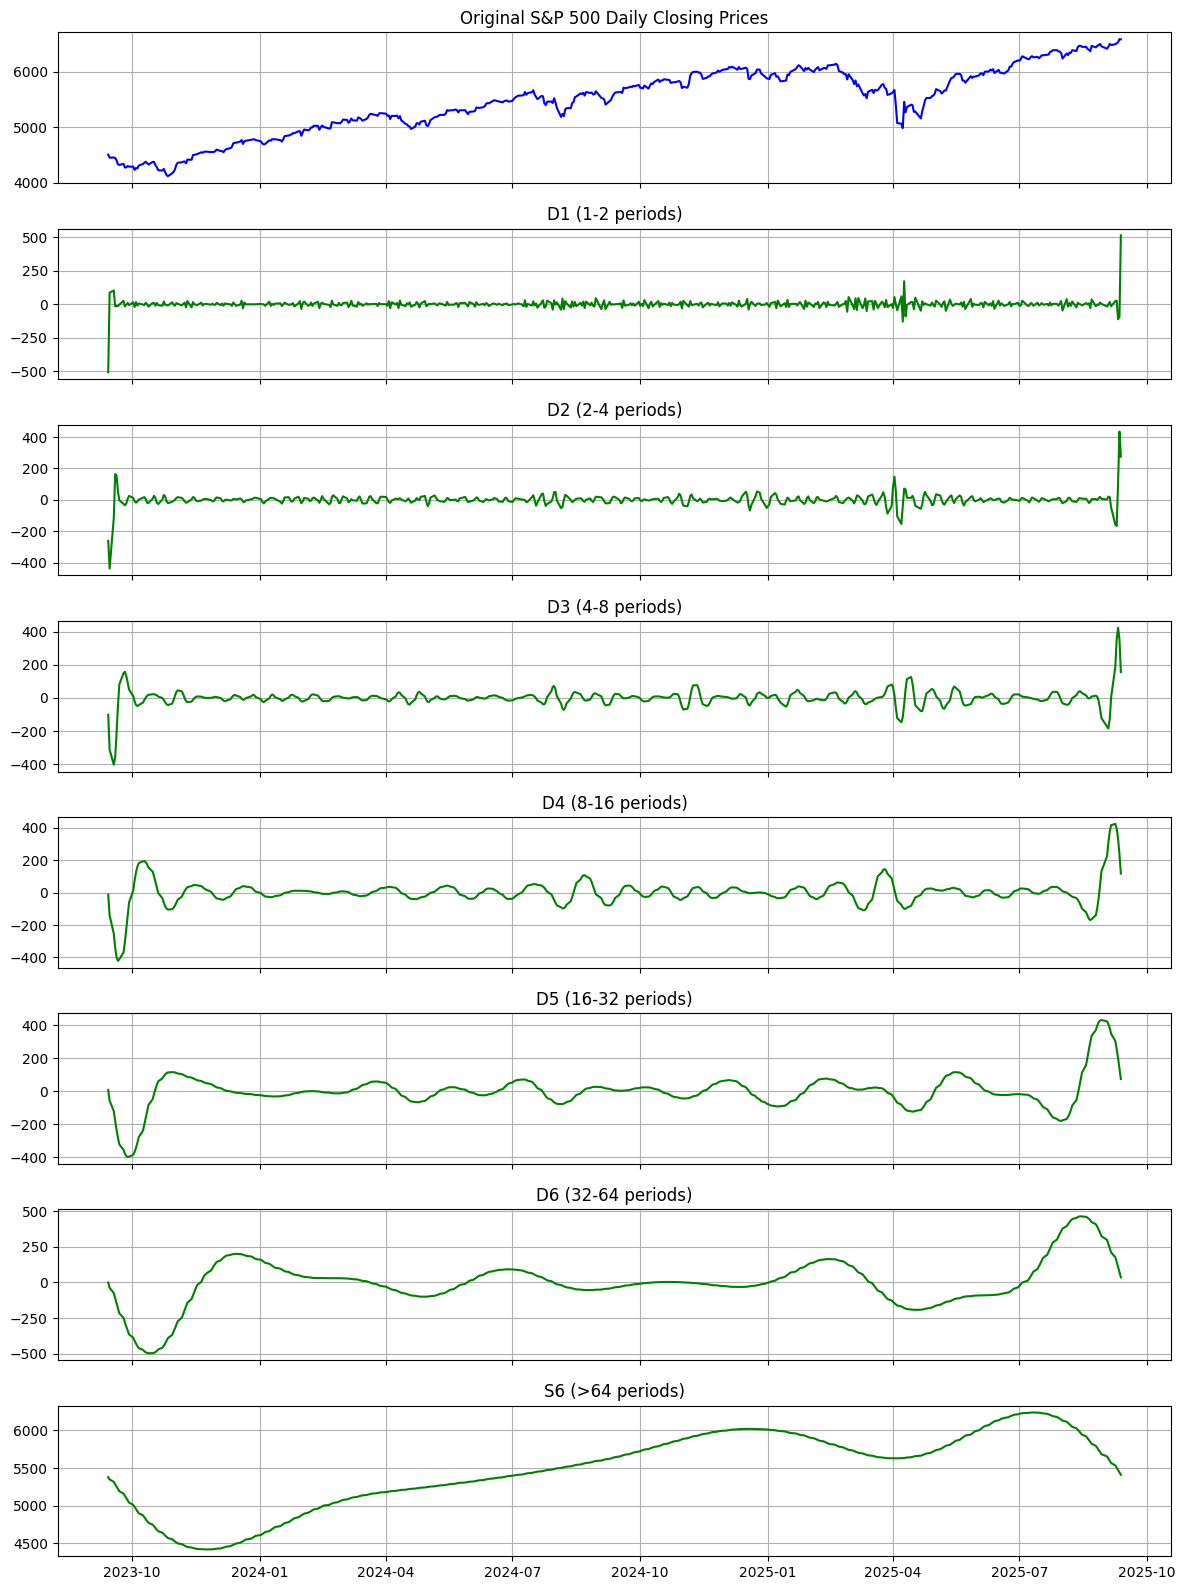

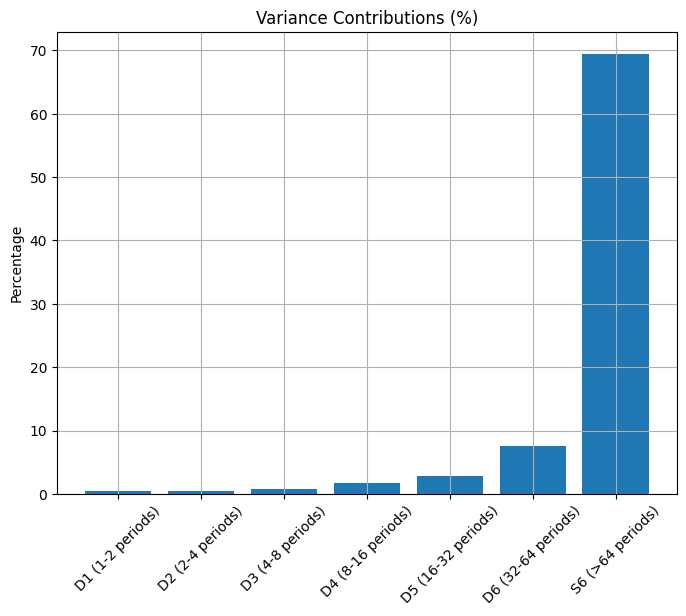

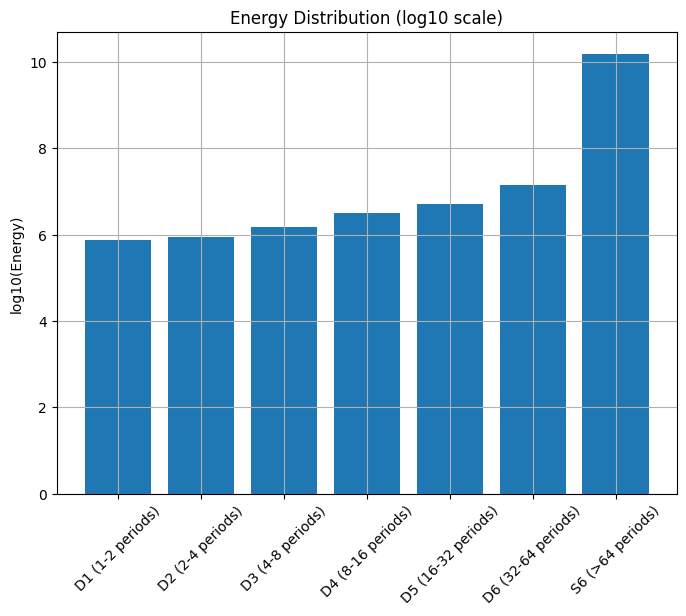


MODWTMRA Analysis Results:
Wavelet used: db4
Decomposition level: 6
Maximum reconstruction error: 9.09e-12

Variance Contributions:
D1 (1-2 periods): 0.42%
D2 (2-4 periods): 0.49%
D3 (4-8 periods): 0.83%
D4 (8-16 periods): 1.74%
D5 (16-32 periods): 2.86%
D6 (32-64 periods): 7.60%
S6 (>64 periods): 69.42%

Total variance accounted for: 83.36%

Financial Market Components Analysis:
Trend volatility (S6): 501.18
Short-term noise volatility (D1+D2): 64.09
Medium-term cycles volatility (D3+D4): 108.12
Long-term cycles volatility (D5+D6): 221.31


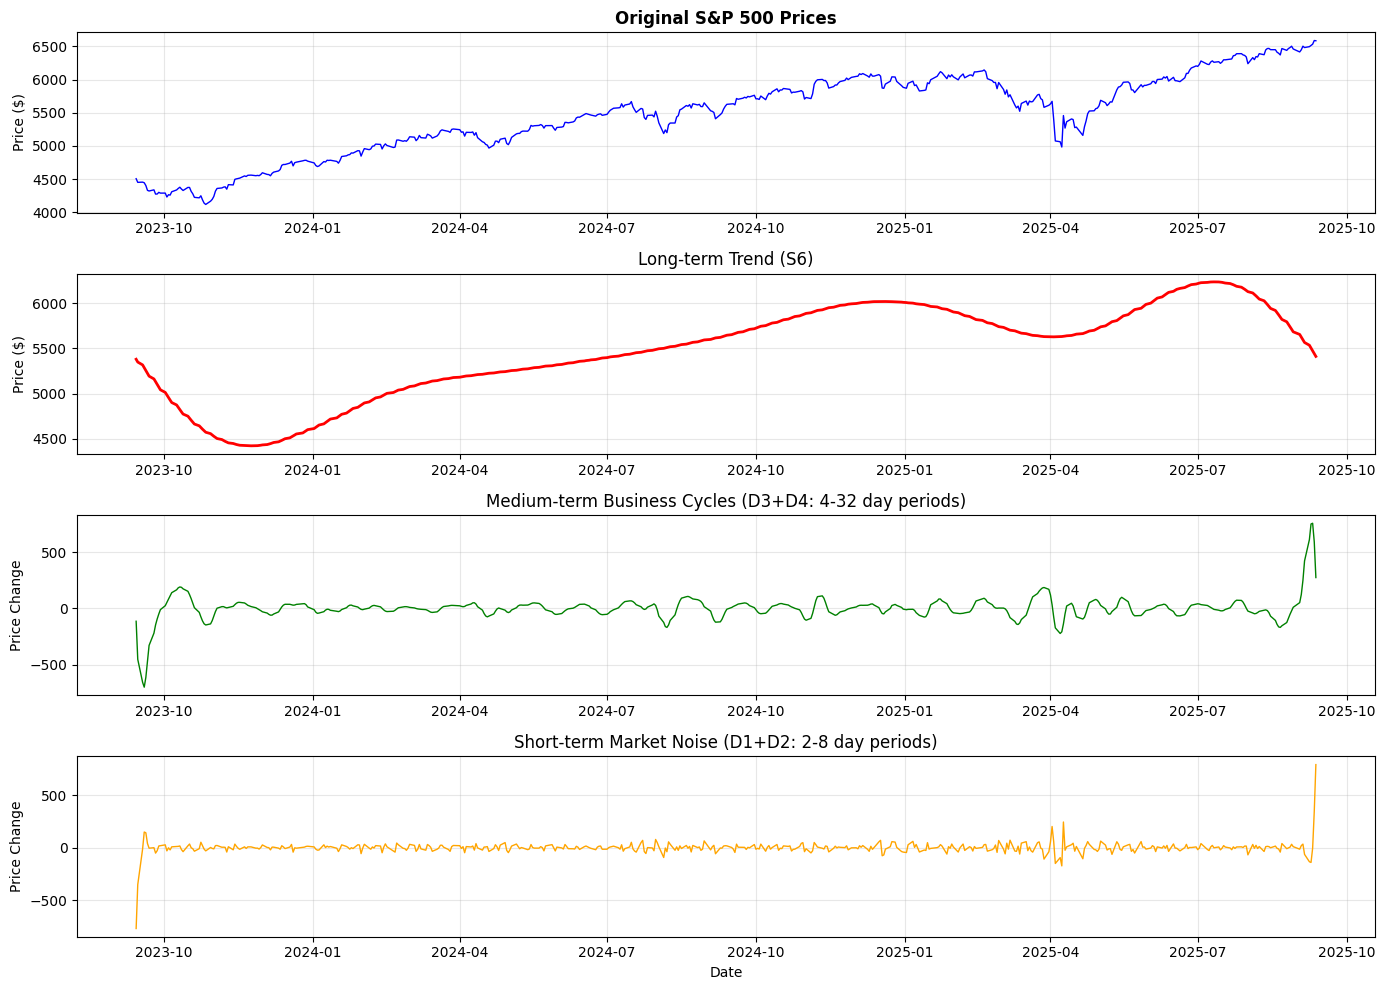


Risk Analysis (Daily Returns):
Total market 5% VaR: -1.477%
Trend component 5% VaR: -0.526%
Market volatility: 1.011%
Trend volatility: 0.214%


In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
from modwtpy.modwt import modwt, modwtmra

# Load data
data_df = prepare_data()

# Extract closing prices and dates
signal = data_df['Close'].values
dates = data_df.index

# Perform comprehensive MODWTMRA analysis
print("Analyzing S&P 500 with MODWTMRA...")
result = analyze_modwtmra(
    signal=signal,
    wavelet='db4',
    level=6,
    plot=True,
    compute_stats=True,
    dates=dates,
    signal_name='S&P 500 Daily Closing Prices'
)

# Display analysis results
print(f"\nMODWTMRA Analysis Results:")
print(f"Wavelet used: {result['wavelet_used']}")
print(f"Decomposition level: {result['level_used']}")
print(f"Maximum reconstruction error: {result['reconstruction_error']:.2e}")

print(f"\nVariance Contributions:")
for i, (label, variance) in enumerate(zip(result['component_labels'], 
                                         result['variance_contributions'])):
    print(f"{label}: {variance:.2f}%")

print(f"\nTotal variance accounted for: {sum(result['variance_contributions']):.2f}%")

# Additional financial analysis using the results
mra_components = result['mra_components']
level = result['level_used']

# Analyze trend and cyclical components
trend = mra_components[-1]  # S6 (smooth component)
short_term_noise = mra_components[0] + mra_components[1]  # D1 + D2
medium_term_cycles = np.sum(mra_components[2:4], axis=0)  # D3 + D4
long_term_cycles = np.sum(mra_components[4:6], axis=0)  # D5 + D6

print(f"\nFinancial Market Components Analysis:")
print(f"Trend volatility (S6): {np.std(trend):.2f}")
print(f"Short-term noise volatility (D1+D2): {np.std(short_term_noise):.2f}")
print(f"Medium-term cycles volatility (D3+D4): {np.std(medium_term_cycles):.2f}")
print(f"Long-term cycles volatility (D5+D6): {np.std(long_term_cycles):.2f}")

# Plot aggregated components for financial interpretation
plt.figure(figsize=(14, 10))

plt.subplot(4, 1, 1)
plt.plot(dates, signal, 'b-', linewidth=1)
plt.title('Original S&P 500 Prices', fontweight='bold')
plt.ylabel('Price ($)')
plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 2)
plt.plot(dates, trend, 'r-', linewidth=2)
plt.title('Long-term Trend (S6)')
plt.ylabel('Price ($)')
plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 3)
plt.plot(dates, medium_term_cycles, 'g-', linewidth=1)
plt.title('Medium-term Business Cycles (D3+D4: 4-32 day periods)')
plt.ylabel('Price Change')
plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 4)
plt.plot(dates, short_term_noise, 'orange', linewidth=1)
plt.title('Short-term Market Noise (D1+D2: 2-8 day periods)')
plt.ylabel('Price Change')
plt.xlabel('Date')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./output/modwtmra_financial_components.png', dpi=300)
plt.show()

# Risk analysis: Compute Value at Risk (VaR)
def compute_var(returns, confidence=0.05):
    """Compute Value at Risk at given confidence level"""
    return np.percentile(returns, confidence * 100)

# Convert to returns for risk analysis
price_returns = np.diff(signal) / signal[:-1] * 100
trend_returns = np.diff(trend) / trend[:-1] * 100

print(f"\nRisk Analysis (Daily Returns):")
print(f"Total market 5% VaR: {compute_var(price_returns, 0.05):.3f}%")
print(f"Trend component 5% VaR: {compute_var(trend_returns, 0.05):.3f}%")
print(f"Market volatility: {np.std(price_returns):.3f}%")
print(f"Trend volatility: {np.std(trend_returns):.3f}%")